In [ ]:
!pip install opencv-python-headless matplotlib scikit-learn scikit-image pytesseract

In [ ]:
!pip install ipywidgets

In [ ]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 85.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 422.8/422.8 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9

In [ ]:
#abir
# STEP 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from skimage.measure import label, regionprops
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from google.colab import files
import pytesseract
import re
import datetime
import os
import pandas as pd
import ipywidgets as widgets
from IPython.display import display

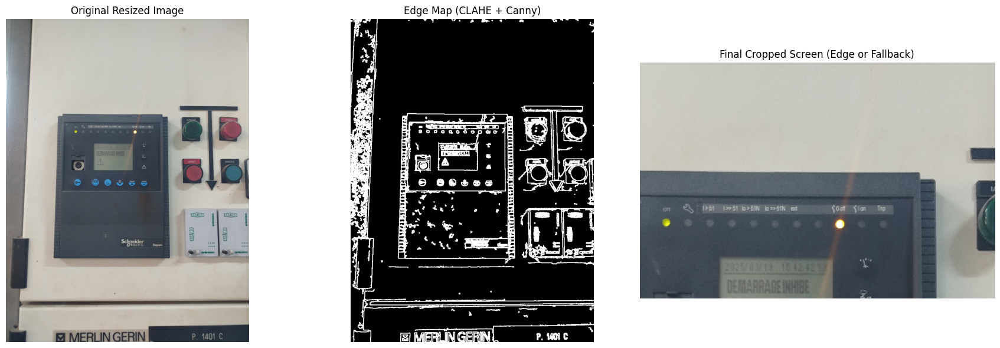

In [ ]:
# #not bad
# def edge_guided_screen_crop(image_path):
#     # Load and resize
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # Convert to grayscale and enhance contrast
#     gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
#     clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
#     enhanced = clahe.apply(gray)

#     # Edge detection
#     edges = cv2.Canny(enhanced, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # Find contours from edges
#     contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx = x + w / 2
#             cy = y + h / 2
#             center_penalty = abs(cx - width / 2) / width + (cy / height)

#             # Check plausible screen size/aspect and prefer top-center regions
#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + center_penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     if best_box:
#         x, y, w, h = best_box
#         padding = 10
#         x = max(x - padding, 0)
#         y = max(y - padding, 0)
#         w = min(w + 2 * padding, width - x)
#         h = min(h + 2 * padding, height - y)
#         cropped = img_resized[y:y+h, x:x+w]
#         return img_resized, cropped, edges

#     # fallback: manually crop top-center box if no good match
#     fx = width // 4
#     fy = int(height * 0.18)
#     fw = width // 2
#     fh = int(height * 0.25)
#     fallback_crop = img_resized[fy:fy+fh, fx:fx+fw]

#     return img_resized, fallback_crop, edges

# # Execute the fallback method on this tricky image
# fallback_img, fallback_crop, fallback_edges = edge_guided_screen_crop("/content/IMG_20250425_151647.jpg")

# # Visualize result
# fig, axes = plt.subplots(1, 3, figsize=(18, 6))
# axes[0].imshow(cv2.cvtColor(fallback_img, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original Resized Image")
# axes[0].axis("off")

# axes[1].imshow(fallback_edges, cmap='gray')
# axes[1].set_title("Edge Map (CLAHE + Canny)")
# axes[1].axis("off")

# axes[2].imshow(cv2.cvtColor(fallback_crop, cv2.COLOR_BGR2RGB))
# axes[2].set_title("Final Cropped Screen (Edge or Fallback)")
# axes[2].axis("off")

# plt.tight_layout()
# plt.show()


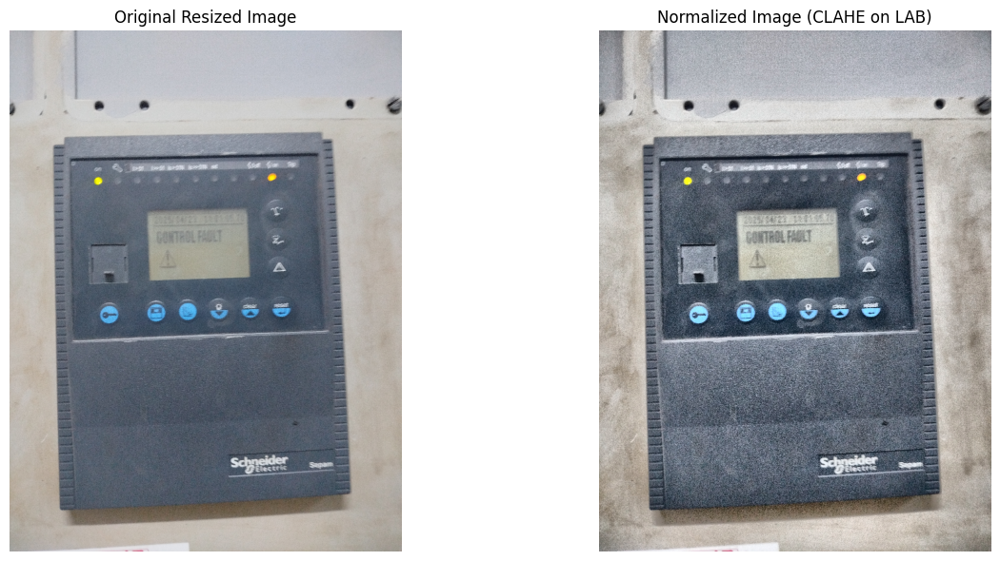

In [ ]:
# def normalize_image_before_crop(image_path):
#     # Load image and resize
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))

#     # Convert to LAB color space for better illumination normalization
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)

#     # Apply CLAHE to L-channel (lightness)
#     clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
#     l_clahe = clahe.apply(l)

#     # Merge back and convert to BGR
#     lab_equalized = cv2.merge((l_clahe, a, b))
#     normalized_img = cv2.cvtColor(lab_equalized, cv2.COLOR_LAB2BGR)

#     return img_resized, normalized_img

# # Run normalization on the newest uploaded image
# original_input, normalized_output = normalize_image_before_crop("/content/IMG_20250425_152038.jpg")

# # Show original vs normalized
# fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# axes[0].imshow(cv2.cvtColor(original_input, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original Resized Image")
# axes[0].axis("off")

# axes[1].imshow(cv2.cvtColor(normalized_output, cv2.COLOR_BGR2RGB))
# axes[1].set_title("Normalized Image (CLAHE on LAB)")
# axes[1].axis("off")

# plt.tight_layout()
# plt.show()


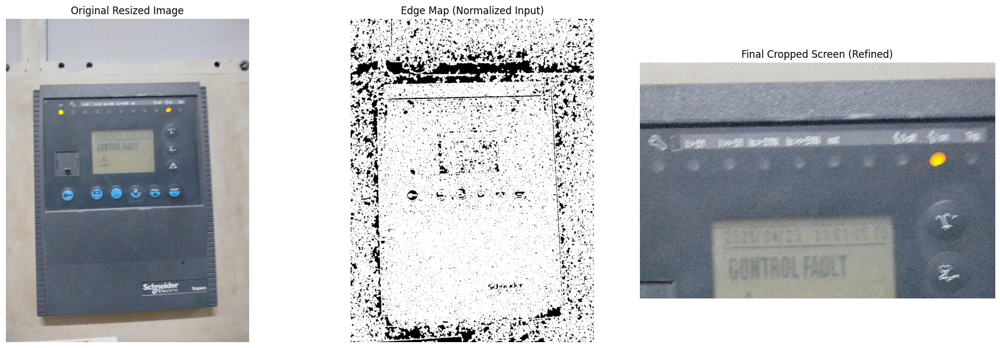

In [ ]:
# # Rewriting edge_guided_screen_crop to include normalized input (LAB+CLAHE)
# def edge_guided_screen_crop_with_normalization(image_path):
#     # Load and resize original image
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # Normalize using LAB + CLAHE
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
#     normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#     # Convert normalized image to grayscale for edge detection
#     gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)

#     # Edge detection
#     edges = cv2.Canny(gray, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # Find contours from edges
#     contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx = x + w / 2
#             cy = y + h / 2
#             center_penalty = abs(cx - width / 2) / width + (cy / height)

#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + center_penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     if best_box:
#         x, y, w, h = best_box
#         padding = 10
#         x = max(x - padding, 0)
#         y = max(y - padding, 0)
#         w = min(w + 2 * padding, width - x)
#         h = min(h + 2 * padding, height - y)
#         cropped = img_resized[y:y+h, x:x+w]
#         return img_resized, cropped, edges

#     # fallback: manually crop top-center box if no good match
#     fx = width // 4
#     fy = int(height * 0.18)
#     fw = width // 2
#     fh = int(height * 0.25)
#     fallback_crop = img_resized[fy:fy+fh, fx:fx+fw]

#     return img_resized, fallback_crop, edges

# # Run the normalized + edge-guided crop
# final_input_img, final_crop_img, final_edge_map = edge_guided_screen_crop_with_normalization("/content/IMG_20250425_152038.jpg")

# # Show output
# fig, axes = plt.subplots(1, 3, figsize=(18, 6))
# axes[0].imshow(cv2.cvtColor(final_input_img, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original Resized Image")
# axes[0].axis("off")

# axes[1].imshow(final_edge_map, cmap='gray')
# axes[1].set_title("Edge Map (Normalized Input)")
# axes[1].axis("off")

# axes[2].imshow(cv2.cvtColor(final_crop_img, cv2.COLOR_BGR2RGB))
# axes[2].set_title("Final Cropped Screen (Refined)")
# axes[2].axis("off")

# plt.tight_layout()
# plt.show()


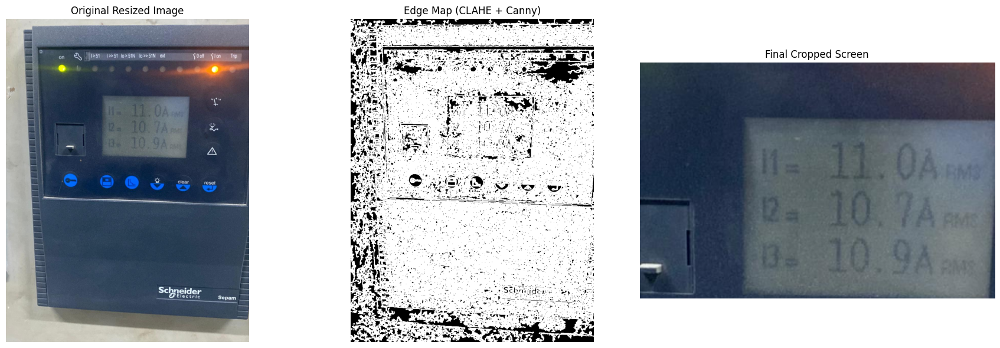

In [ ]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# def normalize_image(img):
#     """Normalize input image using LAB color space and CLAHE on L-channel."""
#     lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(l)
#     lab_equalized = cv2.merge((l_clahe, a, b))
#     return cv2.cvtColor(lab_equalized, cv2.COLOR_LAB2BGR)

# def screen_crop_with_normalization(image_path):
#     # Load and resize
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # Normalize image
#     normalized_img = normalize_image(img_resized)

#     # Convert to grayscale and enhance contrast
#     gray = cv2.cvtColor(normalized_img, cv2.COLOR_BGR2GRAY)
#     clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
#     enhanced = clahe.apply(gray)

#     # Edge detection
#     edges = cv2.Canny(enhanced, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # Find contours
#     contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx = x + w / 2
#             cy = y + h / 2
#             center_penalty = abs(cx - width / 2) / width + (cy / height)

#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + center_penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     if best_box:
#         x, y, w, h = best_box
#         padding = 10
#         x = max(x - padding, 0)
#         y = max(y - padding, 0)
#         w = min(w + 2 * padding, width - x)
#         h = min(h + 2 * padding, height - y)
#         cropped = img_resized[y:y+h, x:x+w]
#         return img_resized, cropped, edges

#     # Fallback crop
#     fx = width // 4
#     fy = int(height * 0.18)
#     fw = width // 2
#     fh = int(height * 0.25)
#     fallback_crop = img_resized[fy:fy+fh, fx:fx+fw]
#     return img_resized, fallback_crop, edges


# # === USAGE ===
# image_path = "/content/WhatsApp Image 2025-05-19 à 18.43.37_d24a3312.jpg"

# original, cropped, edge_map = screen_crop_with_normalization(image_path)

# # Display results
# fig, axes = plt.subplots(1, 3, figsize=(18, 6))
# axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original Resized Image")
# axes[0].axis("off")

# axes[1].imshow(edge_map, cmap='gray')
# axes[1].set_title("Edge Map (CLAHE + Canny)")
# axes[1].axis("off")

# axes[2].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
# axes[2].set_title("Final Cropped Screen")
# axes[2].axis("off")

# plt.tight_layout()
# plt.show()


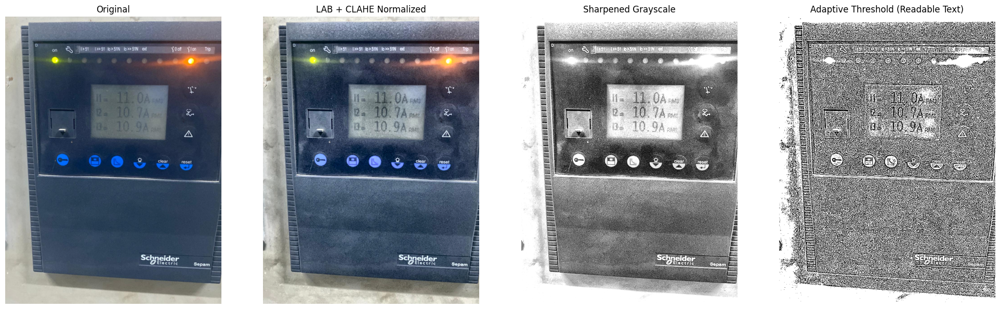

In [ ]:
# def enhance_text_visibility(image_path):
#     # Load and resize image
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))

#     # Normalize lighting using LAB + CLAHE
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(l)
#     lab_eq = cv2.merge((l_clahe, a, b))
#     normalized = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)

#     # Convert to grayscale
#     gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)

#     # Sharpen image using a kernel
#     kernel = np.array([[0, -1, 0],
#                        [-1, 5.5, -1],
#                        [0, -1, 0]])
#     sharpened = cv2.filter2D(gray, -1, kernel)

#     # Binarize using adaptive threshold for OCR-like clarity
#     binarized = cv2.adaptiveThreshold(
#         sharpened, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#         cv2.THRESH_BINARY, 11, 2
#     )

#     return img_resized, normalized, sharpened, binarized

# # Apply to the latest uploaded image
# original_img, normalized_img, sharpened_img, binarized_img = enhance_text_visibility("/content/WhatsApp Image 2025-05-19 à 18.43.37_d24a3312.jpg")

# # Display results
# fig, axes = plt.subplots(1, 4, figsize=(20, 6))
# axes[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original")
# axes[0].axis("off")

# axes[1].imshow(cv2.cvtColor(normalized_img, cv2.COLOR_BGR2RGB))
# axes[1].set_title("LAB + CLAHE Normalized")
# axes[1].axis("off")

# axes[2].imshow(sharpened_img, cmap="gray")
# axes[2].set_title("Sharpened Grayscale")
# axes[2].axis("off")

# axes[3].imshow(binarized_img, cmap="gray")
# axes[3].set_title("Adaptive Threshold (Readable Text)")
# axes[3].axis("off")

# plt.tight_layout()
# plt.show()


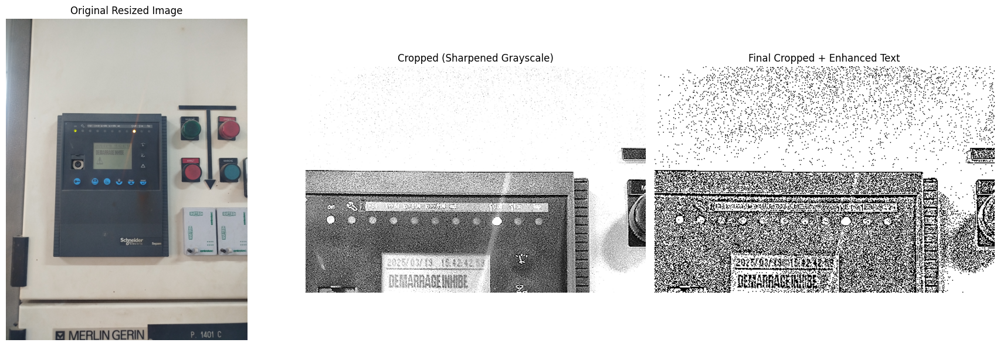

In [ ]:
# #not bad too
# def crop_and_enhance_text(image_path):
#     # Load and resize
#     img = cv2.imread(image_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # --- Normalization ---
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(l)
#     normalized_img = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#     # --- Convert to grayscale & sharpen ---
#     gray = cv2.cvtColor(normalized_img, cv2.COLOR_BGR2GRAY)
#     kernel = np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]])
#     sharpened = cv2.filter2D(gray, -1, kernel)

#     # --- Edge detection ---
#     edges = cv2.Canny(sharpened, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # --- Find contours for cropping ---
#     contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx = x + w / 2
#             cy = y + h / 2
#             center_penalty = abs(cx - width / 2) / width + (cy / height)
#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + center_penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     if best_box:
#         x, y, w, h = best_box
#         padding = 10
#         x = max(x - padding, 0)
#         y = max(y - padding, 0)
#         w = min(w + 2 * padding, width - x)
#         h = min(h + 2 * padding, height - y)
#         cropped_gray = sharpened[y:y+h, x:x+w]
#     else:
#         # fallback crop
#         fx = width // 4
#         fy = int(height * 0.18)
#         fw = width // 2
#         fh = int(height * 0.25)
#         cropped_gray = sharpened[fy:fy+fh, fx:fx+fw]

#     # --- Final text-enhanced binary image ---
#     binarized = cv2.adaptiveThreshold(
#         cropped_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#         cv2.THRESH_BINARY, 11, 2
#     )

#     return img_resized, cropped_gray, binarized

# # Apply it to the latest uploaded image
# orig_img, cropped_text_zone, final_text_enhanced = crop_and_enhance_text('/content/IMG_20250425_151647.jpg')

# # Show output
# fig, axes = plt.subplots(1, 3, figsize=(18, 6))
# axes[0].imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
# axes[0].set_title("Original Resized Image")
# axes[0].axis("off")

# axes[1].imshow(cropped_text_zone, cmap="gray")
# axes[1].set_title("Cropped (Sharpened Grayscale)")
# axes[1].axis("off")

# axes[2].imshow(final_text_enhanced, cmap="gray")
# axes[2].set_title("Final Cropped + Enhanced Text")
# axes[2].axis("off")

# plt.tight_layout()
# plt.show()


In [ ]:
# #not bad version beta
# # STEP 1: Mount Drive
# from google.colab import drive
# drive.mount('/content/drive')

# # STEP 2: Imports
# import cv2
# import numpy as np
# import os

# # STEP 3: Cropping + Text Enhancement Function
# def crop_and_enhance_text(img_path):
#     img = cv2.imread(img_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # Normalize with LAB + CLAHE
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
#     normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#     # Sharpen grayscale
#     gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)
#     sharpened = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))

#     # Edge detection
#     edges = cv2.Canny(sharpened, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # Contour detection
#     contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx, cy = x + w/2, y + h/2
#             penalty = abs(cx - width/2) / width + (cy / height)
#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     if best_box:
#         x, y, w, h = best_box
#         x, y = max(x - 10, 0), max(y - 10, 0)
#         w = min(w + 20, width - x)
#         h = min(h + 20, height - y)
#         cropped = sharpened[y:y+h, x:x+w]
#     else:
#         fx, fy, fw, fh = width//4, int(height*0.18), width//2, int(height*0.25)
#         cropped = sharpened[fy:fy+fh, fx:fx+fw]

#     # Adaptive threshold for text clarity
#     binarized = cv2.adaptiveThreshold(
#         cropped, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#         cv2.THRESH_BINARY, 11, 2
#     )

#     return cropped, binarized

# # STEP 4: Process and Save
# def process_folder(input_folder, out_crop_folder, out_text_folder):
#     os.makedirs(out_crop_folder, exist_ok=True)
#     os.makedirs(out_text_folder, exist_ok=True)
#     for fname in os.listdir(input_folder):
#         if fname.lower().endswith((".png", ".jpg", ".jpeg")):
#             in_path = os.path.join(input_folder, fname)
#             crop, text = crop_and_enhance_text(in_path)
#             cv2.imwrite(os.path.join(out_crop_folder, fname), crop)
#             cv2.imwrite(os.path.join(out_text_folder, fname), text)

# # STEP 5: Define your drive paths
# root = "/content/drive/MyDrive/"
# process_folder(
#     input_folder=root + "relai en panne/" + "relai en panne",
#     out_crop_folder=root + "cropped/en panne",
#     out_text_folder=root + "cropped_text/en panne"
# )

# process_folder(
#     input_folder=root + "relai normal/" + "relai normal",
#     out_crop_folder=root + "cropped/normal",
#     out_text_folder=root + "cropped_text/normal"
# )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# # STEP 1: Mount Drive
# from google.colab import drive
# drive.mount('/content/drive')

# # STEP 2: Imports
# import cv2
# import numpy as np
# import os

# # STEP 3: Screen crop with color + enhanced text
# def color_guided_screen_crop(img_path):
#     img = cv2.imread(img_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
#     lower_screen = np.array([40, 10, 100])
#     upper_screen = np.array([90, 60, 255])
#     mask = cv2.inRange(hsv, lower_screen, upper_screen)

#     mask = cv2.medianBlur(mask, 5)
#     mask = cv2.dilate(mask, None, iterations=3)

#     contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         x, y, w, h = cv2.boundingRect(cnt)
#         area = w * h
#         aspect_ratio = w / h if h != 0 else 0
#         cx, cy = x + w / 2, y + h / 2
#         center_penalty = abs(cx - width / 2) / width + (cy / height)
#         if 1.1 < aspect_ratio < 3.5 and area > 10000:
#             score = area / (1 + center_penalty * 2)
#             if score > best_score:
#                 best_score = score
#                 best_box = (x, y, w, h)

#     if best_box:
#         x, y, w, h = best_box
#         padding = 10
#         x = max(x - padding, 0)
#         y = max(y - padding, 0)
#         w = min(w + 2 * padding, width - x)
#         h = min(h + 2 * padding, height - y)
#         cropped = img_resized[y:y+h, x:x+w]
#     else:
#         fx, fy = width // 4, int(height * 0.18)
#         fw, fh = width // 2, int(height * 0.25)
#         cropped = img_resized[fy:fy+fh, fx:fx+fw]

#     return cropped

# def enhance_text(cropped):
#     lab = cv2.cvtColor(cropped, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
#     normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#     gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)
#     sharpened = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))
#     binarized = cv2.adaptiveThreshold(sharpened, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#                                       cv2.THRESH_BINARY, 11, 2)
#     return binarized

# # STEP 4: Processing loop
# def process_drive_folder(input_folder, crop_folder, text_folder):
#     os.makedirs(crop_folder, exist_ok=True)
#     os.makedirs(text_folder, exist_ok=True)

#     for fname in os.listdir(input_folder):
#         if fname.lower().endswith((".png", ".jpg", ".jpeg")):
#             in_path = os.path.join(input_folder, fname)
#             cropped = color_guided_screen_crop(in_path)
#             enhanced = enhance_text(cropped)

#             cv2.imwrite(os.path.join(crop_folder, fname), cropped)
#             cv2.imwrite(os.path.join(text_folder, fname), enhanced)

# # STEP 5: Apply to your folders
# base = "/content/drive/MyDrive"
# process_drive_folder(f"{base}/relai en panne/relai en panne", f"{base}/cropped/en panne", f"{base}/cropped_text/en panne")
# process_drive_folder(f"{base}/relai normal/relai normal", f"{base}/cropped/normal", f"{base}/cropped_text/normal")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:


# # STEP 3: Cropping + Text Enhancement Function
# def crop_and_enhance_text(img_path):
#     img = cv2.imread(img_path)
#     img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#     height, width = img_resized.shape[:2]

#     # Normalize with LAB + CLAHE
#     lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
#     normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#     # Sharpen grayscale for edge detection
#     gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)
#     sharpened = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))

#     # Edge detection
#     edges = cv2.Canny(sharpened, 50, 150)
#     edges = cv2.dilate(edges, None, iterations=1)

#     # Contour detection
#     contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#     best_box = None
#     best_score = 0

#     for cnt in contours:
#         approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
#         if len(approx) == 4:
#             x, y, w, h = cv2.boundingRect(approx)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx, cy = x + w/2, y + h/2
#             penalty = abs(cx - width/2) / width + (cy / height)
#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + penalty * 2)
#                 if score > best_score:
#                     best_box = (x, y, w, h)
#                     best_score = score

#     # Crop using best box (in COLOR) or fallback
#     if best_box:
#         x, y, w, h = best_box
#         x, y = max(x - 10, 0), max(y - 10, 0)
#         w = min(w + 20, width - x)
#         h = min(h + 20, height - y)
#         cropped_color = img_resized[y:y+h, x:x+w]
#         cropped_gray = sharpened[y:y+h, x:x+w]
#     else:
#         fx, fy, fw, fh = width//4, int(height*0.18), width//2, int(height*0.25)
#         cropped_color = img_resized[fy:fy+fh, fx:fx+fw]
#         cropped_gray = sharpened[fy:fy+fh, fx:fx+fw]

#     # Text enhancement
#     binarized = cv2.adaptiveThreshold(
#         cropped_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#         cv2.THRESH_BINARY, 11, 2
#     )

#     return cropped_color, binarized

# # STEP 4: Process and Save
# def process_folder(input_folder, out_crop_folder, out_text_folder):
#     os.makedirs(out_crop_folder, exist_ok=True)
#     os.makedirs(out_text_folder, exist_ok=True)
#     for fname in os.listdir(input_folder):
#         if fname.lower().endswith((".png", ".jpg", ".jpeg")):
#             in_path = os.path.join(input_folder, fname)
#             crop, text = crop_and_enhance_text(in_path)
#             cv2.imwrite(os.path.join(out_crop_folder, fname), crop)
#             cv2.imwrite(os.path.join(out_text_folder, fname), text)

# # STEP 5: Define your drive paths
# root = "/content/drive/MyDrive/"

# process_folder(
#     input_folder=os.path.join(root, "relai en panne", "relai en panne"),
#     out_crop_folder=os.path.join(root, "cropped/en panne"),
#     out_text_folder=os.path.join(root, "cropped_text/en panne")
# )

# process_folder(
#     input_folder=os.path.join(root, "relai normal", "relai normal"),
#     out_crop_folder=os.path.join(root, "cropped/normal"),
#     out_text_folder=os.path.join(root, "cropped_text/normal")
# )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# # STEP 1: Mount Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

# # STEP 2: Import Dependencies
# import cv2
# import numpy as np
# import os

# # STEP 3: Cropping and Enhancing Function
# def crop_and_enhance_text_color_based(img_path):
#     try:
#         img = cv2.imread(img_path)
#         if img is None:
#             raise ValueError("Image not loaded.")

#         img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
#         height, width = img_resized.shape[:2]

#         # Color detection using HSV
#         hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
#         lower_screen = np.array([40, 10, 100])
#         upper_screen = np.array([90, 60, 255])
#         mask = cv2.inRange(hsv, lower_screen, upper_screen)
#         mask = cv2.medianBlur(mask, 5)
#         mask = cv2.dilate(mask, None, iterations=3)

#         contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#         best_box = None
#         best_score = 0

#         for cnt in contours:
#             x, y, w, h = cv2.boundingRect(cnt)
#             area = w * h
#             aspect_ratio = w / h if h != 0 else 0
#             cx, cy = x + w / 2, y + h / 2
#             center_penalty = abs(cx - width / 2) / width + (cy / height)
#             if 1.1 < aspect_ratio < 3.5 and area > 10000:
#                 score = area / (1 + center_penalty * 2)
#                 if score > best_score:
#                     best_score = score
#                     best_box = (x, y, w, h)

#         # Use best box or fallback
#         if best_box:
#             x, y, w, h = best_box
#             x, y = max(x - 10, 0), max(y - 10, 0)
#             w = min(w + 20, width - x)
#             h = min(h + 20, height - y)
#             cropped_color = img_resized[y:y+h, x:x+w]
#         else:
#             fx, fy, fw, fh = width // 4, int(height * 0.18), width // 2, int(height * 0.25)
#             cropped_color = img_resized[fy:fy+fh, fx:fx+fw]

#         # Enhance text
#         lab = cv2.cvtColor(cropped_color, cv2.COLOR_BGR2LAB)
#         l, a, b = cv2.split(lab)
#         l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
#         normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

#         gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)
#         sharpened = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))
#         binarized = cv2.adaptiveThreshold(sharpened, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
#                                           cv2.THRESH_BINARY, 11, 2)

#         return cropped_color, binarized

#     except Exception as e:
#         print(f"⚠️ Error processing {img_path}: {e}")
#         return None, None

# # STEP 4: Processing Logic
# def process_folder(input_folder, out_crop_folder, out_text_folder):
#     os.makedirs(out_crop_folder, exist_ok=True)
#     os.makedirs(out_text_folder, exist_ok=True)

#     for fname in os.listdir(input_folder):
#         if fname.lower().endswith((".png", ".jpg", ".jpeg")):
#             in_path = os.path.join(input_folder, fname)
#             cropped, enhanced = crop_and_enhance_text_color_based(in_path)
#             if cropped is not None and enhanced is not None:
#                 cv2.imwrite(os.path.join(out_crop_folder, fname), cropped)
#                 cv2.imwrite(os.path.join(out_text_folder, fname), enhanced)

# # STEP 5: Define Paths and Run
# base = "/content/drive/MyDrive"

# process_folder(
#     input_folder=os.path.join(base, "relai en panne", "relai en panne"),
#     out_crop_folder=os.path.join(base, "cropped/en panne"),
#     out_text_folder=os.path.join(base, "cropped_text/en panne")
# )



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# STEP 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# STEP 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# STEP 2: Import Dependencies
import cv2
import numpy as np
import os

# STEP 3: Cropping and Enhancing Function (REFINED VERSION)
def crop_and_enhance_strict_green_focus(img_path):
    try:
        img = cv2.imread(img_path)
        if img is None:
            raise ValueError("Image not loaded.")

        img_resized = cv2.resize(img, (800, int(img.shape[0] * 800 / img.shape[1])))
        height, width = img_resized.shape[:2]

        # HSV conversion (focus on Hue/Saturation only)
        hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)

        # Strict green-gray mask: tuned for Sepam screen
        lower_green = np.array([45, 10, 20])   # ignore brightness (value)
        upper_green = np.array([85, 80, 255])
        mask = cv2.inRange(hsv, lower_green, upper_green)

        # Clean up mask
        mask = cv2.medianBlur(mask, 5)
        mask = cv2.dilate(mask, None, iterations=4)

        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        screen_contours = [c for c in contours if cv2.contourArea(c) > 8000]

        best_box = None
        best_score = 0

        for cnt in screen_contours:
            x, y, w, h = cv2.boundingRect(cnt)
            aspect_ratio = w / h if h != 0 else 0
            cx, cy = x + w / 2, y + h / 2
            center_penalty = abs(cx - width / 2) / width + (cy / height)
            if 1.1 < aspect_ratio < 3.5:
                score = w * h / (1 + center_penalty * 2)
                if score > best_score:
                    best_box = (x, y, w, h)
                    best_score = score

        # Crop from best screen box or fallback
        if best_box:
            x, y, w, h = best_box
            x, y = max(x - 10, 0), max(y - 10, 0)
            w = min(w + 20, width - x)
            h = min(h + 20, height - y)
            cropped_color = img_resized[y:y+h, x:x+w]
        else:
            # fallback region
            fx, fy = width // 4, int(height * 0.18)
            fw, fh = width // 2, int(height * 0.25)
            cropped_color = img_resized[fy:fy+fh, fx:fx+fw]

        # === TEXT ENHANCEMENT ===
        lab = cv2.cvtColor(cropped_color, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = cv2.createCLAHE(clipLimit=3.0).apply(l)
        normalized = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

        gray = cv2.cvtColor(normalized, cv2.COLOR_BGR2GRAY)
        sharpened = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))
        binarized = cv2.adaptiveThreshold(sharpened, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv2.THRESH_BINARY, 11, 2)

        return cropped_color, binarized

    except Exception as e:
        print(f"⚠️ Error processing {img_path}: {e}")
        return None, None

# STEP 4: Processing Logic
def process_folder(input_folder, out_crop_folder, out_text_folder):
    os.makedirs(out_crop_folder, exist_ok=True)
    os.makedirs(out_text_folder, exist_ok=True)

    for fname in os.listdir(input_folder):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            in_path = os.path.join(input_folder, fname)
            cropped, enhanced = crop_and_enhance_strict_green_focus(in_path)
            if cropped is not None and enhanced is not None:
                cv2.imwrite(os.path.join(out_crop_folder, fname), cropped)
                cv2.imwrite(os.path.join(out_text_folder, fname), enhanced)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# STEP 5: Define Paths and Run
base = "/content/drive/MyDrive"

process_folder(
    input_folder=os.path.join(base, "relai en panne/relai en panne"),
    out_crop_folder=os.path.join(base, "cropped/en panne"),
    out_text_folder=os.path.join(base, "cropped_text/en panne")
)

In [ ]:

process_folder(
    input_folder=os.path.join(base, "relai normal/relai normal"),
    out_crop_folder=os.path.join(base, "cropped/normal"),
    out_text_folder=os.path.join(base, "cropped_text/normal")
)

In [ ]:
#labelisation pour entrainer le modele de classification / modele supervisee alerte;warning  / valeur value
image_dir = "/content/drive/MyDrive/cropped/en panne"
image_files = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg'))])
label_data = pd.DataFrame(columns=["filename", "screen_type"])

img_widget = widgets.Image(format='png', width=400)
dropdown = widgets.Dropdown(options=['value', 'warning'], description='Type:')
button = widgets.Button(description='Next')
output = widgets.Output()
index = 0

def show_image(index):
    img_path = os.path.join(image_dir, image_files[index])
    img = cv2.imread(img_path)
    _, buffer = cv2.imencode('.png', img)
    img_widget.value = buffer.tobytes()

def on_next(b):
    global index, label_data
    label = dropdown.value
    row = pd.DataFrame([{"filename": image_files[index], "screen_type": label}])
    label_data = pd.concat([label_data, row], ignore_index=True)
    index += 1
    if index < len(image_files):
        show_image(index)
    else:
        output.clear_output()
        with output:
            display(widgets.HTML("<b>✅ Labeling done.</b>"))
        label_data.to_csv("/content/drive/MyDrive/screen_type_labels1.csv", index=False)

button.on_click(on_next)
show_image(index)
display(widgets.VBox([img_widget, dropdown, button, output]))


In [ ]:
# Load previous labels if they exist
csv_path = "/content/drive/MyDrive/screen_type_labels.csv"
if os.path.exists(csv_path):
    existing_labels = pd.read_csv(csv_path)
    labeled_set = set(existing_labels["filename"])
else:
    existing_labels = pd.DataFrame(columns=["filename", "screen_type", "source_folder"])
    labeled_set = set()

# 📁 Only label from the NEW folder
image_dir = "/content/drive/MyDrive/cropped/normal"
image_files = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg')) and f not in labeled_set])

# Prepare entries for new images
image_entries = [{
    "folder": image_dir,
    "filename": f,
    "path": os.path.join(image_dir, f)
} for f in image_files]

# UI
img_widget = widgets.Image(format='png', width=500)
dropdown = widgets.Dropdown(options=['value', 'warning'], description='Type:')
button = widgets.Button(description='Next')
output = widgets.Output()
index = 0

def show_image(idx):
    img = cv2.imread(image_entries[idx]["path"])
    _, buffer = cv2.imencode('.png', img)
    img_widget.value = buffer.tobytes()
    dropdown.value = 'value'

def on_next(b):
    global index, existing_labels
    entry = image_entries[index]
    row = pd.DataFrame([{
        "filename": entry["filename"],
        "source_folder": os.path.basename(entry["folder"]),
        "screen_type": dropdown.value
    }])
    existing_labels = pd.concat([existing_labels, row], ignore_index=True)
    index += 1
    if index < len(image_entries):
        show_image(index)
    else:
        output.clear_output()
        with output:
            display(widgets.HTML("<b>✅ All new images labeled and saved!</b>"))
        existing_labels.to_csv(csv_path, index=False)

button.on_click(on_next)
if image_entries:
    show_image(index)
    display(widgets.VBox([img_widget, dropdown, button, output]))
else:
    print("✅ No new images left to label.")

✅ No new images left to label.


In [ ]:
import pandas as pd

# Load the labeled CSV
csv_path = "/content/drive/MyDrive/screen_type_labels.csv"
df = pd.read_csv(csv_path)

# Replace NaN in source_folder with "en panne"
df["source_folder"] = df["source_folder"].fillna("en panne")

# Save it back
df.to_csv(csv_path, index=False)

# Show how many replacements were made
replacements = (df["source_folder"] == "en panne").sum()
replacements


np.int64(341)

In [ ]:
# ✅ Full PyTorch Training Script with Train/Validation Split for Value vs Warning Classification
#1er essai sans partie test (dakhltlou data kol )
import os
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Step 1: Load CSV and split into train/val
csv_path = "/content/drive/MyDrive/screen_type_labels.csv"
df = pd.read_csv(csv_path)

# Map text labels to integers
label_map = {"value": 0, "warning": 1}
df['label'] = df['screen_type'].map(label_map)

# Split
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

# Step 2: Dataset class
class SepamDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        folder = row["source_folder"]
        image_path = f"/content/drive/MyDrive/cropped/{folder}/{row['filename']}"
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = int(row["label"])
        return image, label

# Step 3: Transforms and Dataloaders
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = SepamDataset(train_df, transform=transform)
val_dataset = SepamDataset(val_df, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

# Step 4: CNN model
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.model(x)

# Step 5: Train function
def train_model(model, train_loader, val_loader, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
        acc = correct / len(train_loader.dataset)

        # Validation
        model.eval()
        val_correct = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_correct += (outputs.argmax(1) == labels).sum().item()
        val_acc = val_correct / len(val_loader.dataset)

        print(f"Epoch {epoch+1}/{epochs} - Train Acc: {acc:.3f} - Val Acc: {val_acc:.3f}")

    return model

# Step 6: Train and save model
model = SimpleCNN()
trained_model = train_model(model, train_loader, val_loader, epochs=10)
torch.save(trained_model.state_dict(), "/content/drive/MyDrive/sepam_screen_model.pth")


Epoch 1/10 - Train Acc: 0.713 - Val Acc: 0.756
Epoch 2/10 - Train Acc: 0.787 - Val Acc: 0.927
Epoch 3/10 - Train Acc: 0.895 - Val Acc: 0.878
Epoch 4/10 - Train Acc: 0.901 - Val Acc: 0.866
Epoch 5/10 - Train Acc: 0.904 - Val Acc: 0.902
Epoch 6/10 - Train Acc: 0.963 - Val Acc: 0.963
Epoch 7/10 - Train Acc: 0.975 - Val Acc: 0.988
Epoch 8/10 - Train Acc: 0.981 - Val Acc: 0.988
Epoch 9/10 - Train Acc: 0.951 - Val Acc: 0.988
Epoch 10/10 - Train Acc: 0.975 - Val Acc: 0.963


In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image

# Step 1: Recreate the model architecture
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.model(x)

# Step 2: Load model weights
model = SimpleCNN()
model.load_state_dict(torch.load("/content/drive/MyDrive/sepam_screen_model.pth", map_location=torch.device('cpu')))
model.eval()

# Step 3: Define transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Step 4: Load and preprocess image
img_path = "/content/drive/MyDrive/cropped/en panne/1.jpg"  # 👈 Replace with your test image path
image = Image.open(img_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0)

# Step 5: Predict
with torch.no_grad():
    output = model(input_tensor)
    predicted_class = torch.argmax(output, dim=1).item()

label_map = {0: "value", 1: "warning"}
print("Predicted screen type:", label_map[predicted_class])


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/sepam_screen_model.pth'

In [ ]:
# Full modeling setup with auto-split: train on 90%, reserve 10% of images for testing (per class)
#added partie test
import os
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Load and preprocess the full label CSV
csv_path = "/content/drive/MyDrive/screen_type_labels.csv"
df = pd.read_csv(csv_path)
df['label'] = df['screen_type'].map({'value': 0, 'warning': 1})

# Stratified split: 80% train, 10% val, 10% test
train_val_df, test_df = train_test_split(df, test_size=0.1, stratify=df['label'], random_state=42)
train_df, val_df = train_test_split(train_val_df, test_size=0.1111, stratify=train_val_df['label'], random_state=42)  # 0.1111 of 90% = 10%

# Dataset class
class SepamDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = f"/content/drive/MyDrive/cropped/{row['source_folder']}/{row['filename']}"
        image = Image.open(img_path).convert("RGB")
        label = int(row["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

# Image transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Loaders
train_loader = DataLoader(SepamDataset(train_df, transform), batch_size=16, shuffle=True)
val_loader = DataLoader(SepamDataset(val_df, transform), batch_size=16, shuffle=False)
test_loader = DataLoader(SepamDataset(test_df, transform), batch_size=1, shuffle=False)  # For prediction later

# Simple CNN model
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.model(x)

# Train loop
def train_model(model, train_loader, val_loader, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(X)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            train_correct += (out.argmax(1) == y).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # Validation
        model.eval()
        val_correct = 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                out = model(X)
                val_correct += (out.argmax(1) == y).sum().item()
        val_acc = val_correct / len(val_loader.dataset)

        print(f"Epoch {epoch+1}: Train Acc = {train_acc:.3f}, Val Acc = {val_acc:.3f}")
    return model

# Train and save
model = SimpleCNN()
trained_model = train_model(model, train_loader, val_loader, epochs=10)
torch.save(trained_model.state_dict(), "/content/drive/MyDrive/sepam_screen_model.pth")

# Save test set for later use
test_df.to_csv("/content/drive/MyDrive/screen_type_test_set.csv", index=False)


Epoch 1: Train Acc = 0.713, Val Acc = 0.756
Epoch 2: Train Acc = 0.870, Val Acc = 0.902
Epoch 3: Train Acc = 0.843, Val Acc = 0.902
Epoch 4: Train Acc = 0.917, Val Acc = 0.854
Epoch 5: Train Acc = 0.926, Val Acc = 0.927
Epoch 6: Train Acc = 0.960, Val Acc = 0.927
Epoch 7: Train Acc = 0.944, Val Acc = 0.878
Epoch 8: Train Acc = 0.978, Val Acc = 0.976
Epoch 9: Train Acc = 0.972, Val Acc = 0.976
Epoch 10: Train Acc = 0.975, Val Acc = 0.976


In [ ]:
# Load model, test set, and run predictions on held-out test images

import os
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import pandas as pd

# Load test set
test_df = pd.read_csv("/content/drive/MyDrive/screen_type_test_set.csv")
test_df['label'] = test_df['screen_type'].map({'value': 0, 'warning': 1})

# Define transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Recreate dataset class
class SepamDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = f"/content/drive/MyDrive/cropped/{row['source_folder']}/{row['filename']}"
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = int(row["label"])
        return image, label, row["filename"]

# Load test dataset
test_dataset = SepamDataset(test_df, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# Load model
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128), nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.model(x)

# Load trained model
model = SimpleCNN()
model.load_state_dict(torch.load("/content/drive/MyDrive/sepam_screen_model.pth", map_location=torch.device("cpu")))
model.eval()

# Run predictions
predictions = []
correct = 0
for images, labels, filenames in test_loader:
    outputs = model(images)
    preds = outputs.argmax(1).item()
    actual = labels.item()
    predictions.append({
        "filename": filenames[0],
        "actual": "value" if actual == 0 else "warning",
        "predicted": "value" if preds == 0 else "warning",
        "correct": actual == preds
    })
    if preds == actual:
        correct += 1

# Save results
results_df = pd.DataFrame(predictions)
results_df.to_csv("/content/drive/MyDrive/screen_type_test_predictions.csv", index=False)

# Show accuracy
accuracy = correct / len(predictions)
accuracy, results_df.head(10)


(0.9512195121951219,
                                             filename   actual predicted  \
 0  WhatsApp Image 2025-05-19 à 18.38.53_44e60e6d...  warning   warning   
 1                            IMG_20250425_152112.jpg  warning   warning   
 2                            IMG_20250425_152150.jpg  warning   warning   
 3                          IMG_20250425_152152_1.jpg  warning   warning   
 4                          IMG_20250425_152009_2.jpg  warning   warning   
 5  WhatsApp Image 2025-05-19 à 18.44.24_f4f4cd1d...    value     value   
 6                            IMG_20250425_151825.jpg  warning   warning   
 7                          IMG_20250425_152145_2.jpg  warning   warning   
 8                            IMG-20250426-WA0022.jpg    value     value   
 9                            IMG_20250425_151859.jpg  warning   warning   
 
    correct  
 0     True  
 1     True  
 2     True  
 3     True  
 4     True  
 5     True  
 6     True  
 7     True  
 8     True  
 

In [ ]:
# import pandas as pd
# import cv2
# import pytesseract
# import numpy as np

# # Load prediction results and merge with source folder info
# pred_df = pd.read_csv("/content/drive/MyDrive/screen_type_test_predictions.csv")
# meta_df = pd.read_csv("/content/drive/MyDrive/screen_type_test_set.csv")
# df = pd.merge(pred_df, meta_df[["filename", "source_folder"]], on="filename", how="left")

# # Helper to extract warning message
# def extract_warning_text(img_path):
#     img = cv2.imread(img_path)
#     gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#     sharp = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))
#     return pytesseract.image_to_string(sharp, config="--psm 6").strip()

# # Helper to extract I1/I2/I3 values from value screen
# def extract_value_lines(img_path):
#     img = cv2.imread(img_path)
#     gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#     sharp = cv2.filter2D(gray, -1, np.array([[0, -1, 0], [-1, 5.5, -1], [0, -1, 0]]))
#     h = gray.shape[0]
#     lines = []
#     for i in range(3):
#         roi = sharp[i*h//3:(i+1)*h//3, :]
#         text = pytesseract.image_to_string(roi, config="--psm 7").strip()
#         lines.append(text)
#     return lines

# # Process each predicted image
# final_outputs = []
# for _, row in df.iterrows():
#     img_path = f"/content/drive/MyDrive/cropped/{row['source_folder']}/{row['filename']}"

#     if row['predicted'] == "value":
#         I1, I2, I3 = extract_value_lines(img_path)
#         final_outputs.append({
#             "filename": row['filename'],
#             "predicted_type": "value",
#             "I1": I1, "I2": I2, "I3": I3,
#             "warning_message": ""
#         })
#     else:
#         message = extract_warning_text(img_path)
#         final_outputs.append({
#             "filename": row['filename'],
#             "predicted_type": "warning",
#             "I1": "", "I2": "", "I3": "",
#             "warning_message": message
#         })

# # Save the final result
# output_df = pd.DataFrame(final_outputs)
# output_df.to_csv("/content/drive/MyDrive/final_screen_text_outputs.csv", index=False)


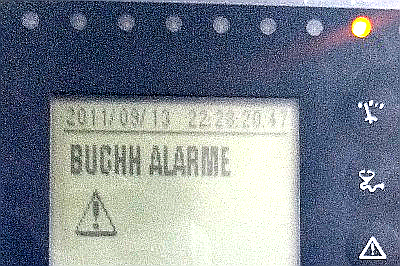

In [ ]:
#important enhance
from PIL import Image, ImageEnhance, ImageFilter
# Apply more aggressive sharpening and contrast enhancement using PIL
enhanced_pil = Image.open( "/content/IMG_20250425_152254_1.jpg")

# Increase contrast
contrast_enhancer = ImageEnhance.Contrast(enhanced_pil)
enhanced_pil = contrast_enhancer.enhance(2.5)  # More aggressive contrast

# Increase sharpness
sharpness_enhancer = ImageEnhance.Sharpness(enhanced_pil)
enhanced_pil = sharpness_enhancer.enhance(5.0)  # Strong sharpening
enhanced_pil


In [ ]:
import easyocr

reader = easyocr.Reader(['en'], gpu=True)

# Limit recognition to uppercase letters, digits, and a few symbols
custom_chars = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.-:/_'

results = reader.readtext(
    '/content/IMG_20250425_152118.jpg',
    detail=0,
    allowlist=custom_chars
)

print("Results:", results)


Results: [([[64, 104], [104, 104], [104, 130], [64, 130]], '4-', 0.039527920122256734), ([[63, 139], [237, 139], [237, 181], [63, 181]], 'BUCHH-ALARAUE', 0.24711350745789426)]


📝 OCR Results: ['N2', '10.94/A', '122', '10.74', 'F', 'B', '10.94A8']


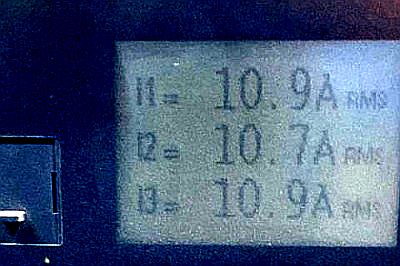

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr

# Step 1: Load and enhance the image
image_path = "/content/WhatsApp Image 2025-05-19 à 18.43.40_4f72e49b.jpg"
image = Image.open(image_path)

# Apply contrast and sharpness enhancement
image = ImageEnhance.Contrast(image).enhance(2.5)
image = ImageEnhance.Sharpness(image).enhance(5.0)

# Convert PIL image to NumPy array for EasyOCR
enhanced_np = np.array(image)

# Step 2: Run EasyOCR on the enhanced image
reader = easyocr.Reader(['en'], gpu=True)

# Restrict OCR to known characters
custom_chars = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.-:/_'

results = reader.readtext(
    enhanced_np,
    detail=0,              # Only return text
    allowlist=custom_chars # Restrict to uppercase letters, digits, etc.
)

# Step 3: Print the OCR results
print("📝 OCR Results:", results)
image

🧾 OCR Text: I= 57.74 RM: I2= 57.64 RME 13= 57.9ARM:
✅ Final Extracted Float Values: ['57.7', '57.6', '57.9']


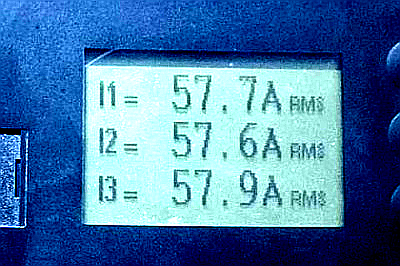

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import re

# === Load and enhance image ===
image_path = "/content/WhatsApp Image 2025-05-19 à 18.42.18_b069cb98.jpg"
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(3.0)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR ===
reader = easyocr.Reader(['en'], gpu=False)
raw_results = reader.readtext(enhanced_np, detail=0, allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.=:/_-')
joined_text = " ".join(raw_results)
print("🧾 OCR Text:", joined_text)

# === Step 3: Grab all float-like values (xx.x or xx.xx), even if followed by junk
raw_floats = re.findall(r'\d{2,3}[.,]\d{1,2}', joined_text)

# Normalize and truncate to 1 decimal
normalized = [x.replace(',', '.')[:4] for x in raw_floats]

# Take only first three
final_values = normalized[:3]


# === Step 5: Output
print("✅ Final Extracted Float Values:", final_values)
image


🧾 OCR Text: N2 10.94 E 12= 10.74 RNS B 10.94AMS
✅ Final Extracted Float Values: ['10.9', '10.7', '10.9']


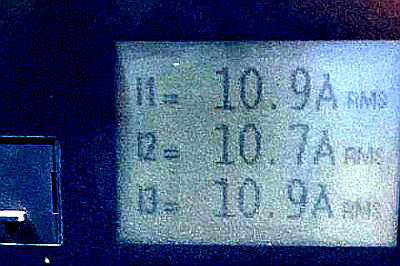

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import re

# === Load and enhance image ===
image_path = "/content/WhatsApp Image 2025-05-19 à 18.43.40_4f72e49b.jpg"
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(3.0)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR ===
reader = easyocr.Reader(['en'], gpu=False)
raw_results = reader.readtext(enhanced_np, detail=0, allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789.=:/_-')
joined_text = " ".join(raw_results)
print("🧾 OCR Text:", joined_text)

# === Step 3: Grab all float-like values (xx.x or xx.xx), even if followed by junk
raw_floats = re.findall(r'\d{2,3}[.,]\d{1,2}', joined_text)

# Normalize and truncate to 1 decimal
normalized = [x.replace(',', '.')[:4] for x in raw_floats]

# Take only first three
final_values = normalized[:3]


# === Step 5: Output
print("✅ Final Extracted Float Values:", final_values)
image


🧾 OCR Text: I= 2.90A-RM: I2= 2.704 RMS 13= 2.70ARM:
✅ Final Extracted Float Values: ['2.90', '2.70', '2.70']


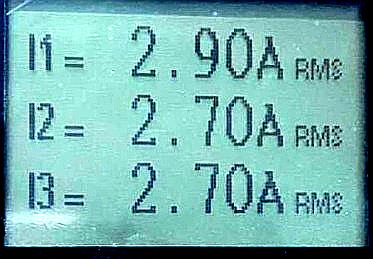

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import re

# === Load and enhance image ===
image_path = "/content/WhatsApp Image 2025-05-19 à 18.42.54_61cf1be0.jpg"
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(3.0)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR ===
reader = easyocr.Reader(['en'], gpu=False)
raw_results = reader.readtext(enhanced_np, detail=0, allowlist='IARMS0123456789.=:/_-')

joined_text = " ".join(raw_results)
print("🧾 OCR Text:", joined_text)

# === Step 3: Grab all float-like values (xx.x or xx.xx), even if followed by junk
raw_floats = re.findall(r'(\d{1,3}[.,]\d{1,2})', joined_text)


# Normalize and truncate to 1 decimal
normalized = [x.replace(',', '.')[:4] for x in raw_floats]

# Take only first three
final_values = normalized[:3]


# === Step 5: Output
print("✅ Final Extracted Float Values:", final_values)
image

🧾 OCR Text: M2 10.94 R 12= 10.74 RSS 0 10.94AMS
✅ Final Extracted Float Values: ['10.9', '10.7', '10.9']


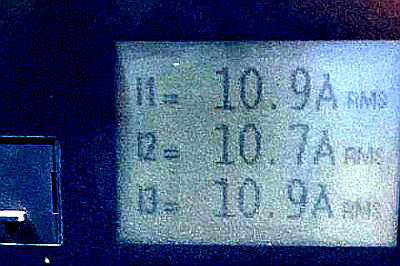

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import re

# === Load and enhance image ===
image_path = "/content/WhatsApp Image 2025-05-19 à 18.43.40_4f72e49b.jpg"
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(3.0)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR ===
reader = easyocr.Reader(['en'], gpu=False)
raw_results = reader.readtext(enhanced_np, detail=0, allowlist='IARMS0123456789.=:/_-')
joined_text = " ".join(raw_results)
print("🧾 OCR Text:", joined_text)

# === Step 3: Grab all float-like values (xx.x or xx.xx), even if followed by junk
raw_floats = re.findall(r'(\d{1,3}[.,]\d{1,2})', joined_text)


# Normalize and truncate to 1 decimal
normalized = [x.replace(',', '.')[:4] for x in raw_floats]

# Take only first three
final_values = normalized[:3]


# === Step 5: Output
print("✅ Final Extracted Float Values:", final_values)
image

ici il faut faire la liaison entre le modele et l'extraction je vais envoye le fichier a la paritie extraction valeur si le modele predicted value ou vers la partie warning si le modele oredicted warning

🧾 OCR Text: 0 000AM 12 00A AM 0.0AR
✅ Final Extracted Float Values: ['0.0']
⚠️  WARNING: At least one extracted value is 0.0 — possible OCR issue or device error.


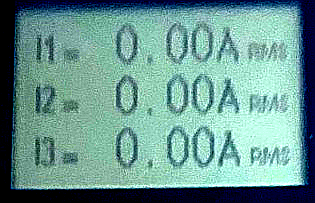

In [ ]:
#this is finalll for valuesss
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import re

# === Load and enhance image ===
image_path = "/content/IMG-20250426-WA0025.jpg" #link is here
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(3.0)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR ===
reader = easyocr.Reader(['en'], gpu=False)
raw_results = reader.readtext(enhanced_np, detail=0, allowlist='IARMS0123456789.=:/_-')
joined_text = " ".join(raw_results)
print("🧾 OCR Text:", joined_text)

# === Step 3: Grab all float-like values (xx.x or xx.xx), even if followed by junk
raw_floats = re.findall(r'(\d{1,3}[.,]\d{1,2})', joined_text)


# Normalize and truncate to 1 decimal
normalized = [x.replace(',', '.')[:4] for x in raw_floats]

# Take only first three
final_values = normalized[:3]


# === Step 5: Output
print("✅ Final Extracted Float Values:", final_values)
# === Step 6: Check for any zero float values ===
if '0.0' in final_values:
    print("⚠️  WARNING: At least one extracted value is 0.0 — possible OCR issue or device error.")
elif len(final_values) < 3:
    print("⚠️  WARNING: Less than 3 valid float values detected.")
else:
    print("✅ Final Extracted Float Values:", final_values)

image

🧾 Detected Expressions: ['011', 'BuGhH AlARME']


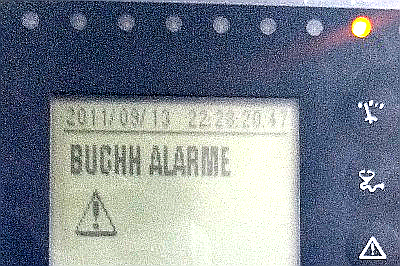

In [ ]:
from PIL import Image, ImageEnhance
import numpy as np
import easyocr

# === Step 1: Load and enhance image ===
image_path = "/content/IMG_20250425_152254_1.jpg"  # update path if needed
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(2.5)
image = ImageEnhance.Sharpness(image).enhance(5.0)
enhanced_np = np.array(image)

# === Step 2: OCR full lines with EasyOCR ===
reader = easyocr.Reader(['fr', 'en'], gpu=False)  # both FR/EN to improve recognition
results = reader.readtext(enhanced_np, detail=0)

# === Step 3: Filter long alphabetic expressions only ===

# === Step 4: Output full expressions ===
print("🧾 Detected Expressions:", results)
image


📄 Full OCR Results: ['u', 'BuGhH AlARME']
✅ Matched Alert(s): ['BUCHH ALARME']


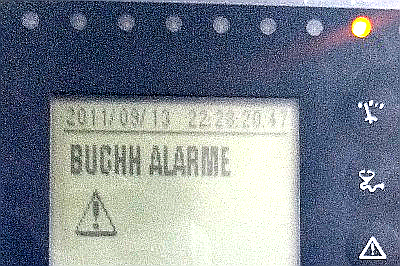

In [ ]:
gfhj#this is final for warning
from PIL import Image, ImageEnhance
import numpy as np
import easyocr
import difflib

# === CONFIG ===
image_path = "/content/IMG_20250425_152254_1.jpg"

known_alerts = [
    'BUCHH ALARME', 'ROTATION', 'SURCHAUFFE', 'PRESSION', 'TEMPÉRATURE',
     'MOTEUR', 'DEF', 'ERREUR', 'PANNE', 'COUPURE',
    'DISJONCTEUR FER', 'ORDRE ARRET EXT', 'TENSION',
    'CONTROL FAULT', 'ECHAUF',
    'DEFAUT', 'TERRE', 'DEMARRAGE INHIBE'
]

def smart_match(text, alerts, cutoff=0.6):
    """Try direct containment and fuzzy match against known alerts"""
    text = text.upper().strip()
    for alert in alerts:
        if alert in text:
            return alert
    guess = difflib.get_close_matches(text, alerts, n=1, cutoff=cutoff)
    return guess[0] if guess else None

# === STEP 1: Load & enhance full image ===
image = Image.open(image_path)
image = ImageEnhance.Contrast(image).enhance(2.5)
image = ImageEnhance.Sharpness(image).enhance(5.0)
image_np = np.array(image)

# === STEP 2: OCR on full image ===
reader = easyocr.Reader(['fr', 'en'], gpu=False)
results_full = reader.readtext(
    image_np,
    detail=0,
    allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz '
)
print("📄 Full OCR Results:", results_full)

# === STEP 3: Match expressions from full image ===
matched = []
for text in results_full:
    match = smart_match(text, known_alerts)
    if match:
        matched.append(match)

# === STEP 4: Try focused crop if nothing matched ===
if not matched:
    crop = image.crop((80, 120, 380, 180))  # Adjust for your layout
    crop = ImageEnhance.Contrast(crop).enhance(2.5)
    crop = ImageEnhance.Sharpness(crop).enhance(5.0)
    crop_np = np.array(crop)

    results_crop = reader.readtext(
        crop_np,
        detail=0,
        allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz '
    )
    print("🔍 OCR from Cropped Zone:", results_crop)

    for text in results_crop:
        match = smart_match(text, known_alerts)
        if match:
            matched.append(match)
# === STEP 5: Final Result ===
if matched:
    print("✅ Matched Alert(s):", list(set(matched)))
else:
    print("⚠️  WARNING: No known alert expression matched.")
    print("🧾 OCR Raw Text Lines (for review):")
    for line in results_full:
        print("•", line)


# === Display the enhanced image ===
image


In [ ]:
#de creer un api pour donner input image output extraction (fast api)